# NYC311: trustworthy Python exploration

AI-assisted portfolio case study. The included runner executes these Python cells using CPython, not a Jupyter kernel. Outputs below come from the pinned source; synthetic boundary fixtures are not mixed with findings.

**Question:** where does January 2024 intake concentrate, and which data-quality issues affect recorded closure reporting?

The source is an October 2026 snapshot of requests *created* in January 2024. Closed is administrative status, not proof of a fix.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
if 'display_png' not in globals():
    from IPython.display import display, Image
    def display_png(path): display(Image(filename=str(path)))
# Supports running from the repository root or notebooks/ in Jupyter.
ROOT = Path.cwd()
if not (ROOT / 'analysis.py').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from analysis import read_snapshot, clean_data, metrics, group_metrics
raw, manifest = read_snapshot(ROOT)
print('Rows:', len(raw), 'Columns:', len(raw.columns))
print('Retrieved:', manifest['retrieval_started_utc'])
print('Raw SHA-256:', manifest['raw_sha256'])
print(raw.dtypes.to_string())
print(raw.head(3).to_string(index=False))

Rows: 287186 Columns: 14
Retrieved: 2026-10-01T20:34:37.917335+00:00
Raw SHA-256: ffaad5274e974cbece133dcf2c8576a96d15d9e6a1cafac9db112a7c2d7de19d
unique_key                        string[python]
created_date                      string[python]
closed_date                       string[python]
agency                            string[python]
agency_name                       string[python]
complaint_type                    string[python]
descriptor                        string[python]
location_type                     string[python]
incident_zip                      string[python]
borough                           string[python]
status                            string[python]
due_date                          string[python]
resolution_action_updated_date    string[python]
open_data_channel_type            string[python]
unique_key            created_date             closed_date agency                     agency_name  complaint_type                    descriptor   location_type inciden

## Inspect first: blanks and duplicate keys
Do not assume blank is the only missing representation. Exact duplicates and repeated request IDs are separate questions; counts below describe the actual snapshot.

In [2]:
inspection = pd.DataFrame({'raw_blanks': raw.eq('').sum(), 'distinct_raw_values': raw.nunique()})
print(inspection.to_string())
print('Exact repeats:', int(raw.duplicated().sum()))
print('Rows with repeated nonblank IDs:', int((raw.unique_key.ne('') & raw.unique_key.duplicated(keep=False)).sum()))

                                raw_blanks  distinct_raw_values
unique_key                               0               287186
created_date                             0               231737
closed_date                           2961               187427
agency                                   0                   14
agency_name                              0                   14
complaint_type                           0                  172
descriptor                            1706                  754
location_type                        33625                  111
incident_zip                          3090                  234
borough                                  0                    6
status                                   0                    7
due_date                            285757                  902
resolution_action_updated_date         458               150313
open_data_channel_type                   0                    5
Exact repeats: 0
Rows with repeated nonb

## Clean with explicit gates
IDs/ZIPs stay strings. Normalize whitespace/null tokens, parse dates, localize New York time, and separate accepted volume from eligible closure timing. No missing dates are filled and no valid outliers are deleted.

In [3]:
clean, quality, quarantine = clean_data(raw, manifest)
print('Accepted:', len(clean), 'Quarantined:', len(quarantine))
missing = pd.DataFrame({'raw_blanks': quality['raw_blank_count'], 'normalized_missing': quality['normalized_missing_count']})
missing['normalized_share'] = missing.normalized_missing / len(raw)
print(missing.to_string())
for key in ['closed_status_missing_close_date','nonclosed_status_with_close_date','negative_duration_requests','future_close_requests','unknown_borough_requests']:
    print(key, quality[key])
print('Parse failures:', quality['date_parse_failures'])
print('DST-unresolved:', quality['timezone_unresolvable_count'])

Accepted: 287186 Quarantined: 0
                                raw_blanks  normalized_missing  normalized_share
unique_key                               0                   0          0.000000
created_date                             0                   0          0.000000
closed_date                           2961                2961          0.010310
agency                                   0                   0          0.000000
agency_name                              0                   0          0.000000
complaint_type                           0                   0          0.000000
descriptor                            1706                7466          0.025997
location_type                        33625               33632          0.117109
incident_zip                          3090                3090          0.010760
borough                                  0                   0          0.000000
status                                   0                   0          0.000

## Check the measurement population
Every accepted request belongs to volume analysis. Timing requires Closed status and a valid nonnegative UTC-adjusted interval, with no future closure. The 75 negative intervals are all non-Closed; they are not an extra subtraction from the Closed count.

In [4]:
overall = metrics(clean)
print(json.dumps(overall, indent=2))
assert overall['requests'] == 287186
assert overall['closed_status'] == 285297
assert overall['timing_eligible'] == 284017
assert clean.loc[clean.negative_duration, 'is_closed'].sum() == 0
print(pd.crosstab(clean.status_clean, clean.closed_date_local.isna(), dropna=False).to_string())

{
  "requests": 287186,
  "closed_status": 285297,
  "not_closed_status": 1889,
  "timing_eligible": 284017,
  "closed_excluded_from_timing": 1280,
  "closed_status_share": 0.9934223813138523,
  "median_hours": 19.1,
  "p90_hours": 668.5463888888889,
  "mean_hours": 317.62980472999857,
  "within_24h": 152789,
  "within_24h_share_of_eligible": 0.5379572349542457,
  "zero_duration": 3809,
  "upper_iqr_outliers": 49374,
  "unknown_zip": 3090,
  "invalid_nonmissing_zip": 0,
  "negative_duration": 75,
  "nonclosed_with_close_date": 208
}
closed_date_local   False  True 
status_clean                    
ASSIGNED               71     90
CLOSED             284017   1280
IN PROGRESS             0   1256
OPEN                   54    165
PENDING                75    109
STARTED                 2     60
UNSPECIFIED             6      1


## Group and aggregate: demand concentration
Use all accepted requests for demand share and a separate timing denominator inside each group. A request is not a unique person or incident.

In [5]:
problems = pd.DataFrame(group_metrics(clean, 'problem_clean'))
problems['request_share'] = problems.requests / len(clean)
print(problems[['name','requests','request_share','timing_eligible','median_hours','p90_hours']].head(10).to_string(index=False))
top3 = int(problems.head(3).requests.sum())
print('Top 3 requests:', top3, 'Share:', f'{top3 / len(clean):.2%}')
assert top3 == 114540
print('Local weekday intake:')
print(clean.groupby('created_weekday', observed=True).size().to_string())
assert clean.groupby('created_weekday', observed=True).size().sum() == len(clean)

                    name  requests  request_share  timing_eligible  median_hours   p90_hours
          HEAT/HOT WATER     51325       0.178717            51259     36.090556   74.095444
         Illegal Parking     41124       0.143196            41123      1.108889    6.151333
     Noise - Residential     22091       0.076922            22088      0.600556    2.417111
        Blocked Driveway     14966       0.052113            14966      1.552639    6.992083
    UNSANITARY CONDITION     10720       0.037328            10715    342.162778 2056.970444
                PLUMBING      6800       0.023678             6783    211.783889 1920.175944
           PAINT/PLASTER      6755       0.023521             6747    202.395000 1556.339056
       Abandoned Vehicle      6079       0.021167             6079      1.536111    9.386222
              WATER LEAK      5863       0.020415             5861    348.318333 2617.210556
Traffic Signal Condition      5225       0.018194             5196    

## Investigate outliers instead of deleting them
The global IQR fence is a review flag. Trace the source dates, and explain how removing valid long or zero durations changes the population and its estimate.

In [6]:
timed = clean.loc[clean.timing_eligible, 'closure_seconds']
print('IQR rule:', quality['outlier_rule'])
print('Long flags:', int(clean.upper_iqr_outlier.sum()), 'Zero durations:', int(timed.eq(0).sum()))
longest = clean.loc[clean.timing_eligible].nlargest(5, 'closure_seconds')
print(longest[['unique_key','agency_clean','problem_clean','created_date','closed_date','closure_seconds']].to_string(index=False))
for label, frame in [('default',clean),('exclude upper fence: diagnostic only',clean.loc[~clean.upper_iqr_outlier]),('exclude zero: diagnostic only',clean.loc[~(clean.timing_eligible & clean.closure_seconds.eq(0))])]:
    m = metrics(frame)
    print(label, 'timed n',m['timing_eligible'],'median h',round(m['median_hours'],2),'mean h',round(m['mean_hours'],2))

IQR rule: {'q1_seconds': 4112.0, 'q3_seconds': 310219.0, 'upper_fence_seconds': 769379.5, 'method': 'global eligible cohort Q3 + 1.5 × IQR; linear quantiles; investigate, do not delete'}
Long flags: 49374 Zero durations: 3809
unique_key agency_clean          problem_clean            created_date             closed_date  closure_seconds
  59916703          DOT Street Light Condition 2024-01-03T14:19:00.000 2026-09-14T13:41:00.000       85098120.0
  60036024          DEP      Sewer Maintenance 2024-01-16T09:04:23.000 2026-09-23T03:30:00.000       84734737.0
  59954444          DOT Street Light Condition 2024-01-07T21:46:00.000 2026-09-08T13:34:00.000       84206880.0
  59897455          DOT Street Light Condition 2024-01-01T23:58:00.000 2026-08-18T17:54:00.000       82918560.0
  60174174          DOT Street Light Condition 2024-01-29T08:05:00.000 2026-09-11T18:09:00.000       82631040.0
default timed n 284017 median h 19.1 mean h 317.63
exclude upper fence: diagnostic only timed n 234643

## Compare one problem across locations
Same-category comparisons reduce one mix difference. They do not control severity, repeat incidents, reporting behavior, or administrative workflow. No causal location ranking is justified.

In [7]:
heat = clean.loc[clean.problem_clean.eq('HEAT/HOT WATER')]
comparison = pd.DataFrame(group_metrics(heat, 'borough_clean'))
print(comparison[['name','requests','timing_eligible','median_hours','p90_hours']].to_string(index=False))

         name  requests  timing_eligible  median_hours  p90_hours
        Bronx     18483            18477     29.589722  63.831500
     Brooklyn     13233            13205     39.966389  74.898833
    Manhattan     11196            11178     45.484028  82.611861
       Queens      7859             7845     36.426944  74.055500
Staten Island       554              554     41.220833  93.397417


## Visual evidence
These five figures are regenerated by `visualize.py` from the exact validated model. Each has a standalone SVG version and explicit scope/denominator.

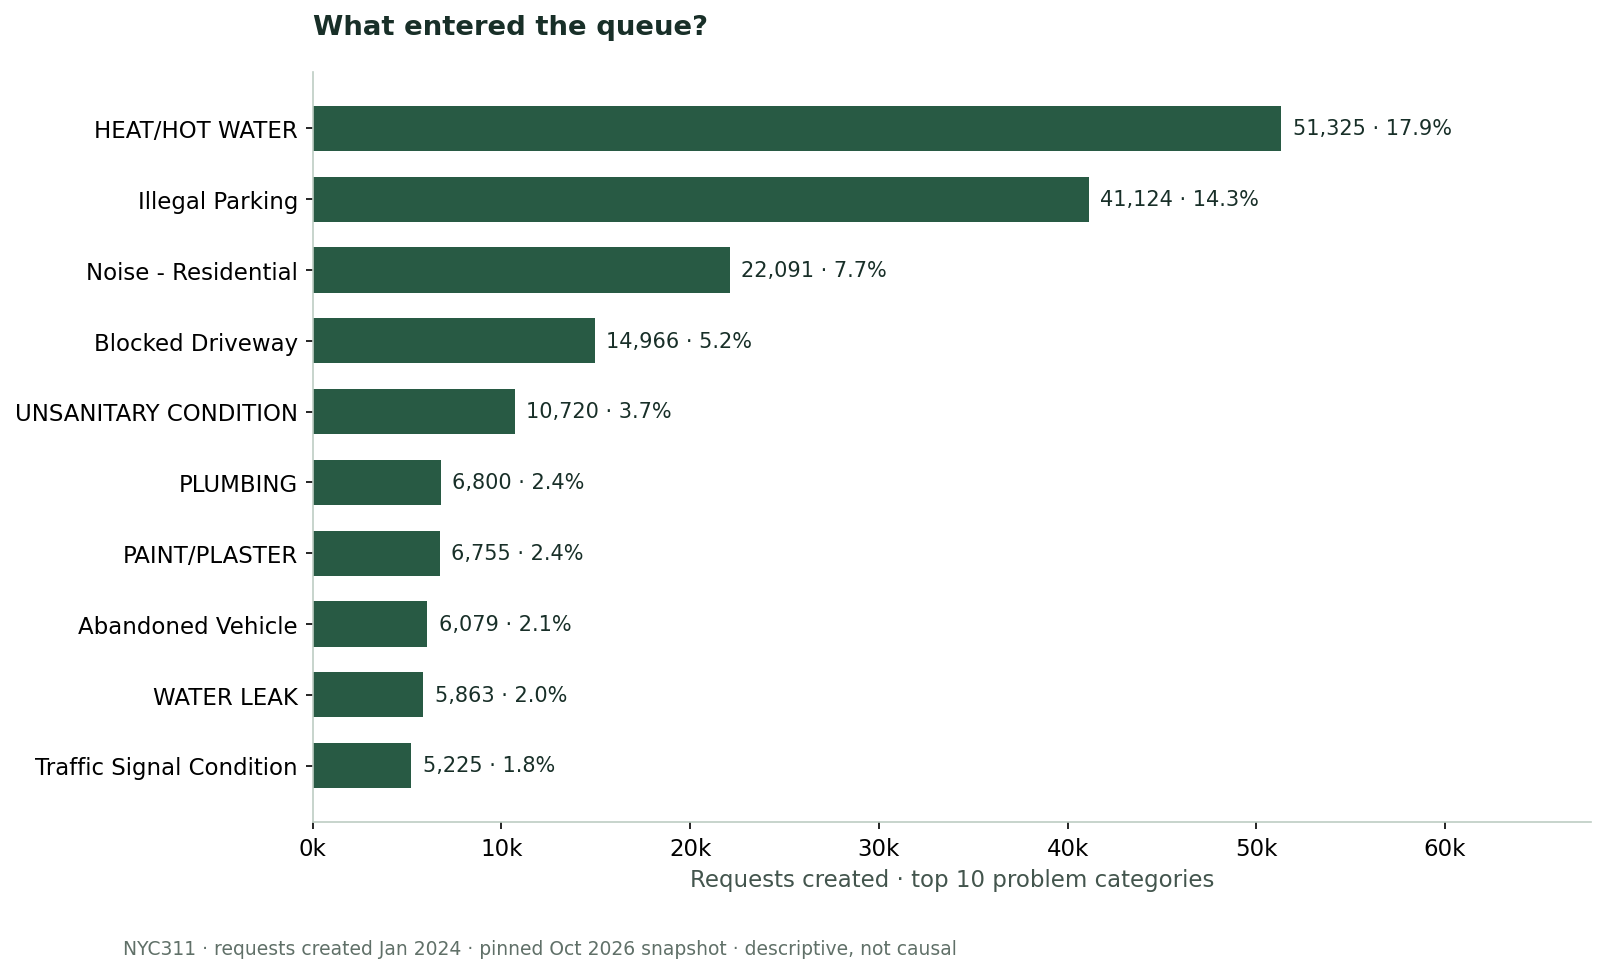

In [8]:
display_png(ROOT / 'figures/problem-volume.png')

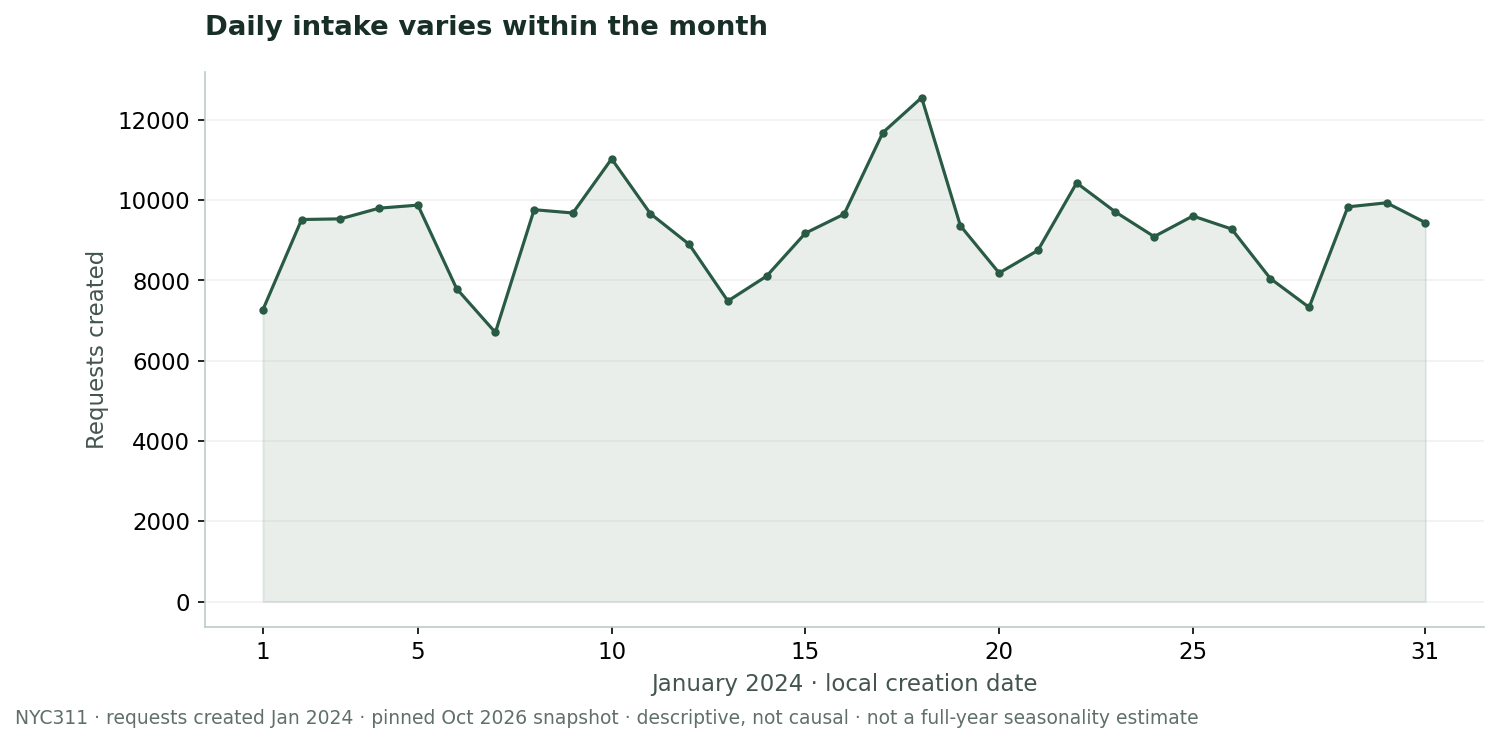

In [9]:
display_png(ROOT / 'figures/daily-intake.png')

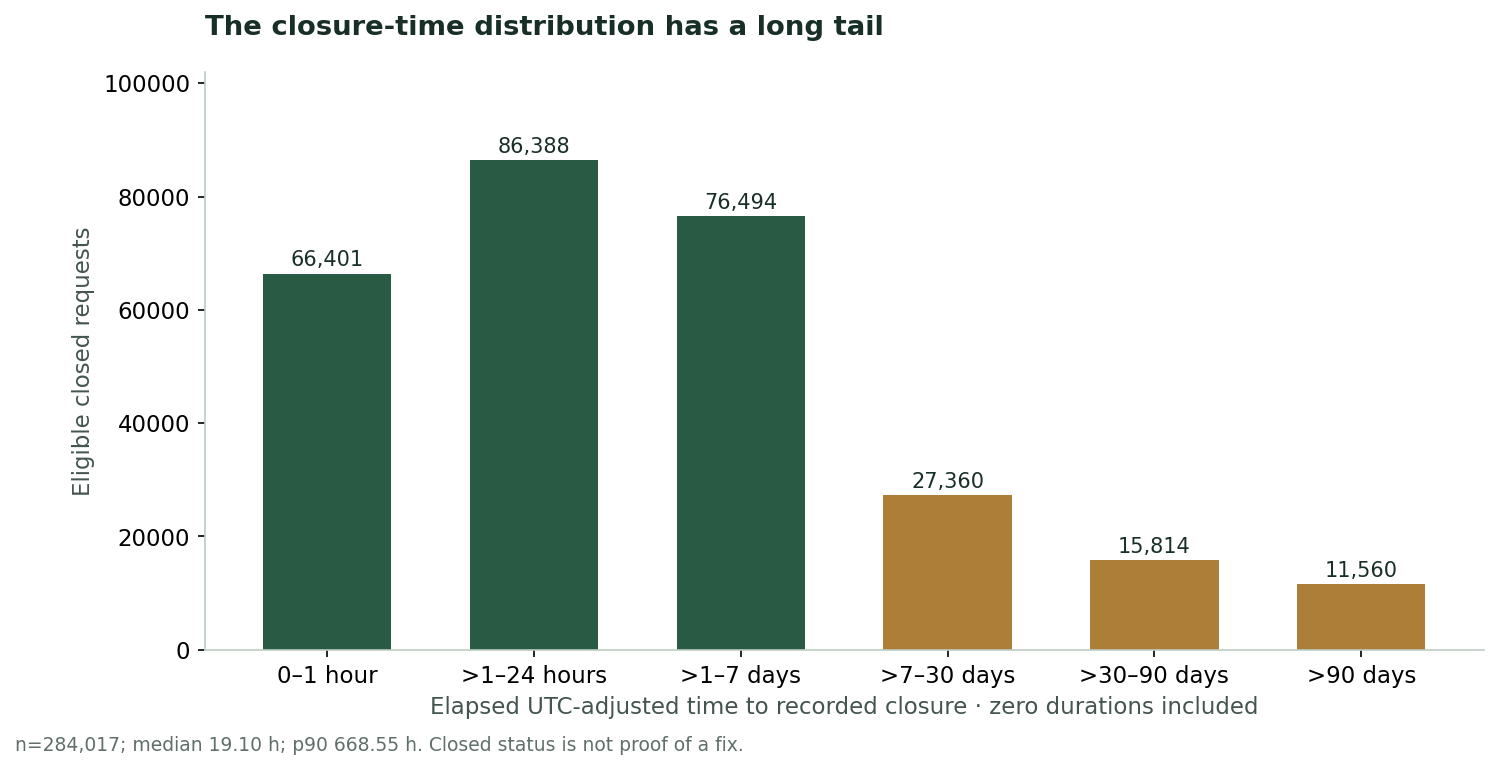

In [10]:
display_png(ROOT / 'figures/closure-distribution.png')

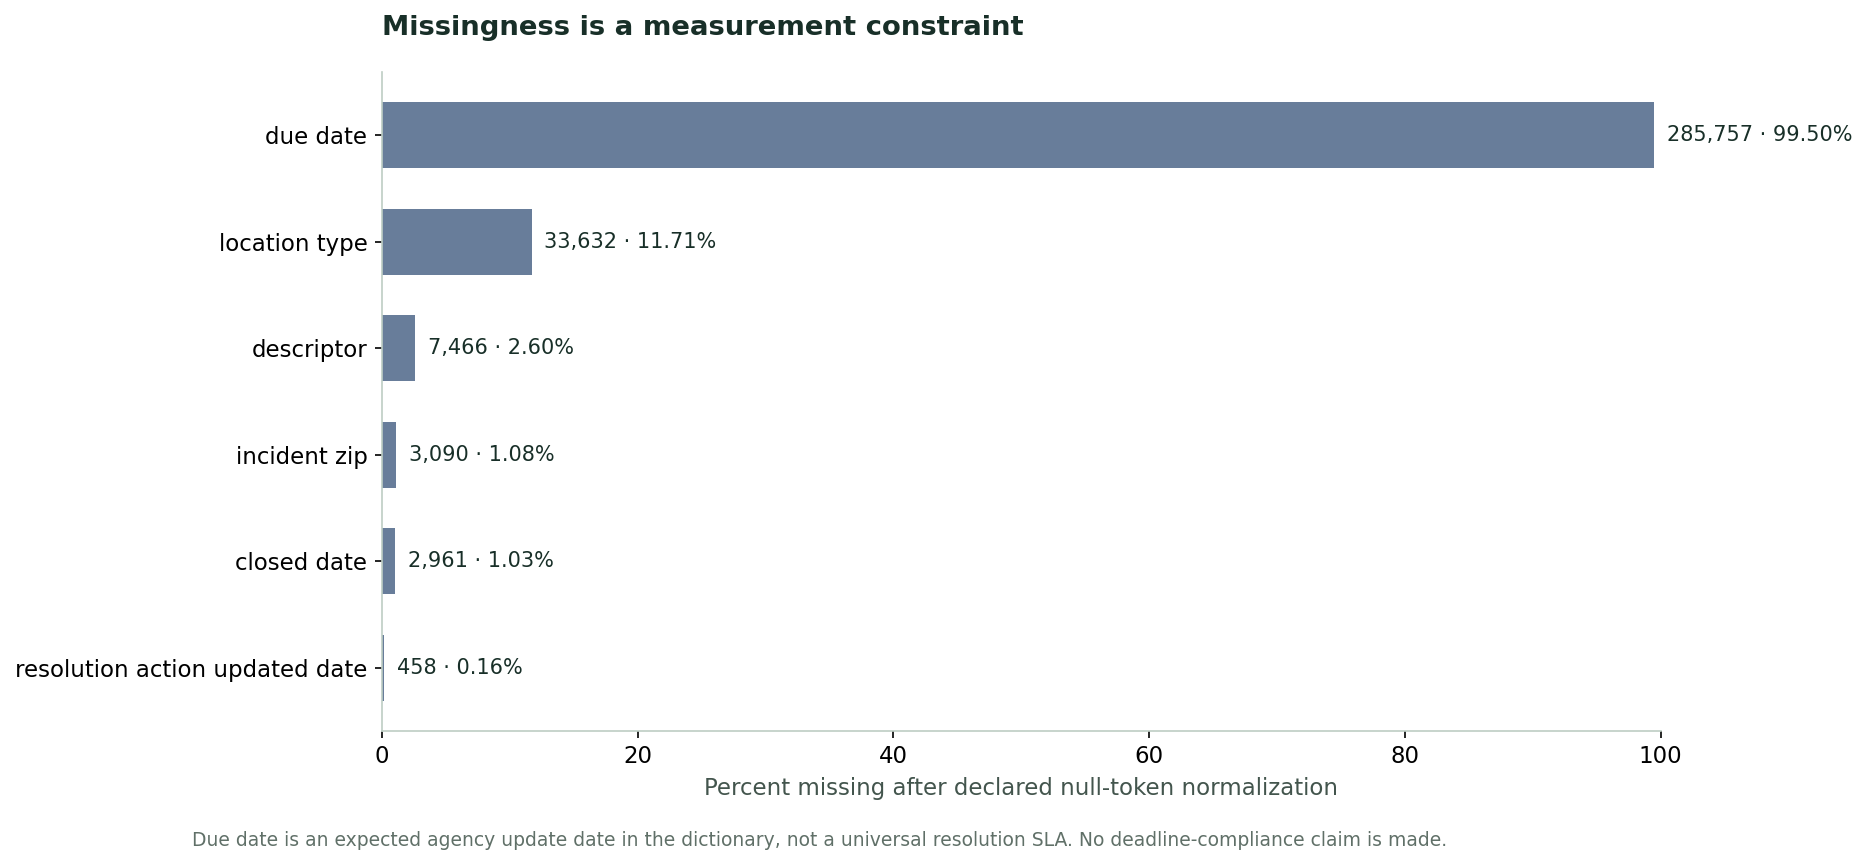

In [11]:
display_png(ROOT / 'figures/missingness.png')

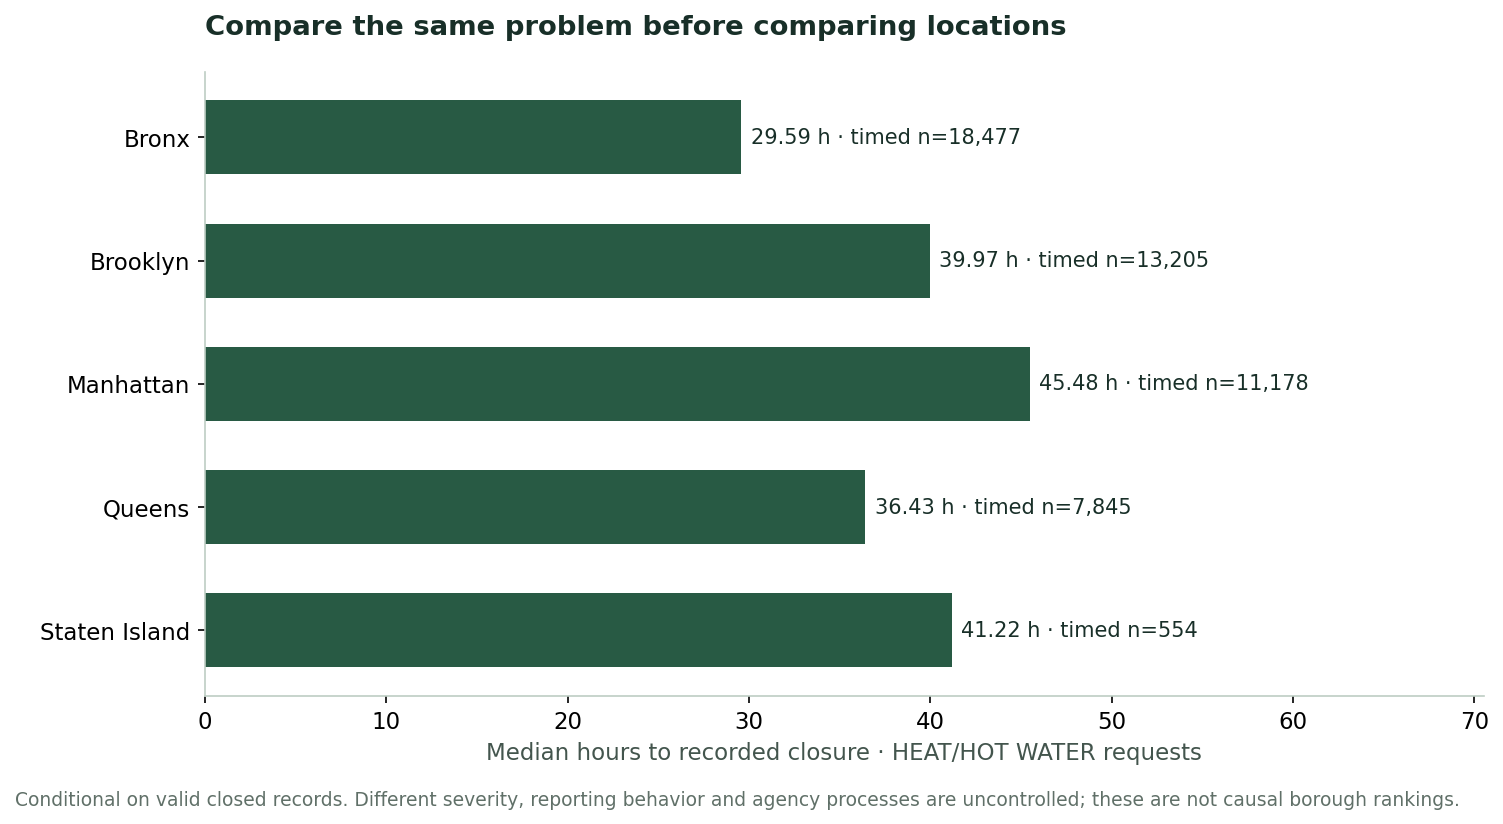

In [12]:
display_png(ROOT / 'figures/same-problem-boroughs.png')

## Validation and limitations
Independent stdlib raw-CSV calculations match all published metrics, distributions, quality audits, 105 filter views, sensitivity views, same-problem comparisons, and outlier traces. Synthetic tests cover absent boundary cases. Source-side totals/groups/days provide a separate extraction control.

One winter month is not annual seasonality. Records are mutable, demand is not population-adjusted, Closed is not proof of repair, and non-Closed/missing-date records are censored from timing estimates. No universal SLA, service outcome, or causal ranking is established. Browser QA and actual Jupyter-kernel execution remain distinct from this CPython cell execution.

In [13]:
evidence = json.loads((ROOT / 'results/validation.json').read_text())
print(json.dumps(evidence, indent=2))
assert evidence['status'] == 'passed'
print('End of executed exploration. See INTERVIEW_BRIEF.md for explanation and practice questions.')

{
  "status": "passed",
  "reference": "raw CSV with independent stdlib csv/datetime/zoneinfo/collections/statistics code; no Pandas cleaning functions",
  "raw_rows_checked": 287186,
  "accepted_requests_checked": 287186,
  "filter_views_checked": 105,
  "scalar_metric_comparisons": 38284,
  "distribution_count_comparisons": 8105,
  "outlier_examples_checked": 12,
  "all_published_agency_borough_problem_channel_metrics_checked": true,
  "same_problem_comparisons_checked": 3,
  "sensitivity_views_checked": 3,
  "source_missingness_whitespace_duplicate_date_and_eligibility_audits_checked": true
}
End of executed exploration. See INTERVIEW_BRIEF.md for explanation and practice questions.
